# Batched propagation: the minimal example

`Propagator.propagate()` (and `ChainPropagator.propagate()`) accept a whole
batch of mode-amplitude vectors, shape `(n_fields, n_modes)`, and propagate
them in a single call: the coupled-mode equations are linear, so every field
shares the same z steps. This notebook uses only cbeam itself, on the 6-port
photonic lantern of the documentation (`docs_source/PL.rst`):

1. build and characterize the lantern (about a minute; cached under `./data`);
2. propagate a batch of input fields in one call, and the same fields one at
   a time, and compare time and results;
3. convert the whole batch to output-core powers at once.

The backend is chosen with `CBEAM_BACKEND` before cbeam is imported; batching
helps on numpy and even more on jax, where every separate call also pays a
dispatch to the device.

In [1]:
import os
os.environ.setdefault("CBEAM_BACKEND", "numpy")

import time
import numpy as np
import matplotlib.pyplot as plt
from cbeam.waveguide import PhotonicLantern
from cbeam.propagator import Propagator

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## The lantern

The 6-port lantern of `docs_source/PL.rst`: one central core and a pentagon
of five, tapering by a factor 8 over 40 mm. Modes 1&2 and 3&4 are degenerate.

In [2]:
wl = 1.55                                   # wavelength, um
taper_factor = 8.
rcore, rclad, rjack, z_ex = 2.2 / taper_factor, 10, 30, 40000
nclad = 1.444
ncore, njack = nclad + 8.8e-3, nclad - 5.5e-3
t = 2 * np.pi / 5
core_pos = np.array([[0, 0]] + [[rclad * 2 / 3 * np.cos(i * t), rclad * 2 / 3 * np.sin(i * t)] for i in range(5)])
lant = PhotonicLantern(core_pos, [rcore] * 6, rclad, rjack, [ncore] * 6, nclad, njack, z_ex, taper_factor)

prop = Propagator(wl, lant, 6)
prop.degen_groups = [[1, 2], [3, 4]]
try:
    prop.load(tag="pl6_minimal")
except FileNotFoundError:
    prop.characterize(save=True, tag="pl6_minimal")

mesh has  8183  points
computing modes ...
current z: 0 / 40000 ; current zstep: 10.0        

current z: 10.0 / 40000 ; current zstep: 10.0        

current z: 20.0 / 40000 ; current zstep: 10.0        

current z: 30.0 / 40000 ; current zstep: 10.0        

current z: 40.0 / 40000 ; current zstep: 10.0        

current z: 60.0 / 40000 ; current zstep: 20.0        

... (364 outputs left out)

current z: 39720.0 / 40000.0        

current z: 39880.0 / 40000.0        

current z: 40000.0 / 40000.0        

time elapsed:  56.47006368637085


## One call for the whole batch

The batch holds the six single-mode launches followed by random unit-norm
superpositions of the six modes.

In [3]:
rng = np.random.default_rng(0)
n_random = 94
u_rand = rng.standard_normal((n_random, 6)) + 1j * rng.standard_normal((n_random, 6))
u0_batch = np.concatenate([np.eye(6), u_rand / np.linalg.norm(u_rand, axis=1, keepdims=True)])
print("batch shape:", u0_batch.shape)

t0 = time.perf_counter()
zs, us, uf_batch = prop.propagate(u0_batch)          # every field at once
t_batch = time.perf_counter() - t0

t0 = time.perf_counter()
uf_loop = np.array([prop.propagate(u)[2] for u in u0_batch])   # one call per field
t_loop = time.perf_counter() - t0

print(f"one batched call : {t_batch:6.2f} s")
print(f"one call / field : {t_loop:6.2f} s   ({t_loop / t_batch:.0f}x slower)")
print(f"largest difference between the two: {np.abs(np.asarray(uf_batch) - uf_loop).max():.1e}")

batch shape: (100, 6)


one batched call :   4.54 s
one call / field :  33.52 s   (7x slower)
largest difference between the two: 2.1e-08


## Output-core powers for the whole batch

`to_channel_basis()` multiplies by the change-of-basis matrix, so the
transposed batch converts every field at once. The first six rows are the
lantern's power transfer matrix: input mode -> output core.

LP01 launch -> core powers: [0.4957 0.1006 0.1004 0.1004 0.1006 0.1005]
total output power per field: min 0.9959, max 0.9983


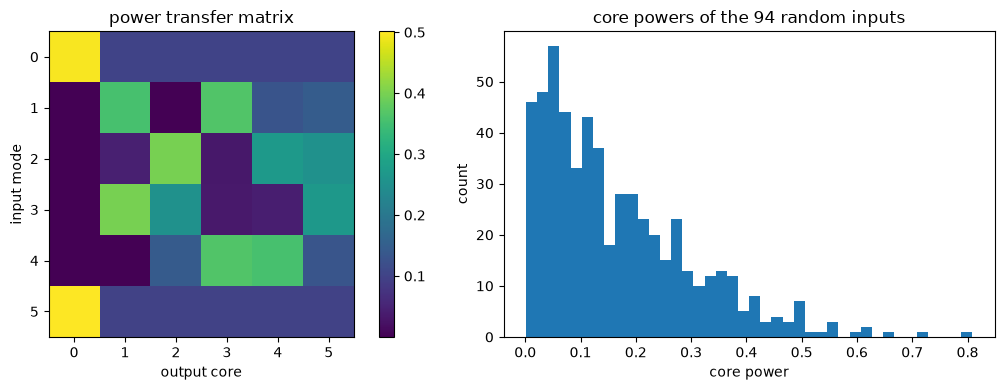

In [4]:
amps = prop.to_channel_basis(np.asarray(uf_batch).T).T     # (n_fields, 6 cores)
powers = np.abs(amps) ** 2
print("LP01 launch -> core powers:", np.round(powers[0], 4))   # cf. docs_source/PL.rst
print("total output power per field: min %.4f, max %.4f" % (powers.sum(1).min(), powers.sum(1).max()))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(powers[:6], cmap="viridis")
ax[0].set_xlabel("output core"); ax[0].set_ylabel("input mode")
ax[0].set_title("power transfer matrix"); plt.colorbar(im, ax=ax[0])
ax[1].hist(powers[6:].ravel(), bins=40)
ax[1].set_xlabel("core power"); ax[1].set_ylabel("count")
ax[1].set_title(f"core powers of the {n_random} random inputs")
plt.tight_layout(); plt.show()